# Longitudinal animal-progress analysis

Cross-session view of how an animal's *strategy* evolves in the Phase 3 cued task -
beyond a single accuracy number. Reads the per-session recordings via the
`tmaze.analysis` layer (all logic is tested there; this notebook is a thin
front-end) and shows:

1. Per-session **progression** (accuracy / reward / bias, with a husbandry ribbon).
2. Rolling **strategy traces** (switch/alternation, win-stay, lose-shift, cue-follow,
   cue-switch->choice-switch), with intervention **blocks shaded**.
3. A rule-based **behavioural-mode decomposition** (disengaged / side-bias /
   alternating / lose-shift / win-stay / cue-following) + occupancy per session.
4. **Peri-intervention transitions**: does an *auto* block instigate a mode switch?
5. **Return-cue carryover**: does trial N-1's return cue bias the choice/switch at N?
6. The per-session **choice-vs-history model** (is cue identity starting to drive
   choice?).

Intervention blocks are kept as first-class labelled epochs (`free` / `in_block` /
`post_block`), never dropped. Notes/caveats:
- No per-excursion log exists for current recordings, so engagement uses an
  inter-trial-gap proxy and the `non-stem` mode reads "no data" until those logs ship.
- The return-cue term is partly endogenous (`return_cue_played` depends on the
  animal's own return path); the model controls for prior choice/reward but the
  result stays observational.

Run inside the `drieu_t_maze` env: `jupyter lab host/notebooks/animal_progress.ipynb`.

In [1]:
## 1. Configuration  -- edit these, then Run All
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tmaze.analysis import (
    bundle_reader,
    choice_signals,
    rolling_metrics,
    mode_label,
    intervention_response,
    choice_model,
)

ANIMALS = ("600", "601", "602")   # which animals to load
START_DATE = "2026-08-03"                  # inclusive "YYYY-MM-DD" lower bound, or None
END_DATE = "2026-08-18"                    # inclusive "YYYY-MM-DD" upper bound, or None
WINDOW = 20                        # rolling window (completed trials)
POST_WINDOW = 10                   # NORMAL trials after a block that count as post-block
PRE_POST = 15                      # peri-intervention pre/post window (trials)
RECORDINGS_ROOT = None             # None -> paths.phase3_recordings_root() (TMAZE_RECORDINGS_DIR)
THRESHOLDS = mode_label.ModeThresholds()  # tune the mode cut-points here

ANIMAL = "602"                     # animal used for the single-animal detail plots
pd.set_option("display.width", 160)

In [2]:
## 2. Load sessions + shared helpers
data = bundle_reader.load_animals(ANIMALS, START_DATE, END_DATE, RECORDINGS_ROOT)
signals = choice_signals.add_signals(data.trials, post_window=POST_WINDOW)
HAS_EXC = rolling_metrics.has_excursion_data(data.excursions)
print(f"Loaded {len(data.sessions)} sessions, {len(signals)} trials; "
      f"per-excursion log present: {HAS_EXC}")


def animal_signals(animal):
    return signals[signals["animal"] == animal].copy()


def session_summary(sig):
    """Per-session free-trial accuracy / reward / side bias, in session order."""
    c = sig[choice_signals.bool_series(sig["completed"])]
    free = c[c["epoch"] == choice_signals.EPOCH_FREE]
    if free.empty:
        return pd.DataFrame()
    return (
        free.groupby(["animal", "session_id", "date"], sort=False)
        .agg(
            n_free=("correct", "size"),
            accuracy=("correct", "mean"),
            reward_rate=("reward", lambda s: (s == 1).mean()),
            side_bias_left=("choice", lambda s: (s == "LEFT").mean()),
        )
        .reset_index()
    )


summ = session_summary(signals)
data.sessions[["session_id", "animal", "date", "generator", "n_trials",
               "stage", "pct_baseline", "hours_since_water"]]

Loaded 39 sessions, 7800 trials; per-excursion log present: False


,session_id,animal,date,generator,n_trials,stage,pct_baseline,hours_since_water
0,600_20260803_125810,600,2026-08-03,,200,,NaN,NaN
1,600_20260804_154539,600,2026-08-04,,200,,NaN,NaN
2,600_20260805_144056,600,2026-08-05,,200,,NaN,NaN
3,600_20260806_150601,600,2026-08-06,,200,,NaN,NaN
4,600_20260807_164732,600,2026-08-07,,200,Phase 3,1.0690,NaN
5,600_20260810_121353,600,2026-08-10,debias_blocks,200,Phase 3,1.1351,NaN
6,600_20260811_151031,600,2026-08-11,debias_blocks,200,Phase 3,NaN,NaN
7,600_20260812_133259,600,2026-08-12,debias_blocks,200,Phase 3,1.0920,NaN
8,600_20260813_144137,600,2026-08-13,debias_blocks,200,Phase 3,1.0862,96.19
9,600_20260814_151843,600,2026-08-14,debias_blocks,200,Phase 3,1.0690,120.81


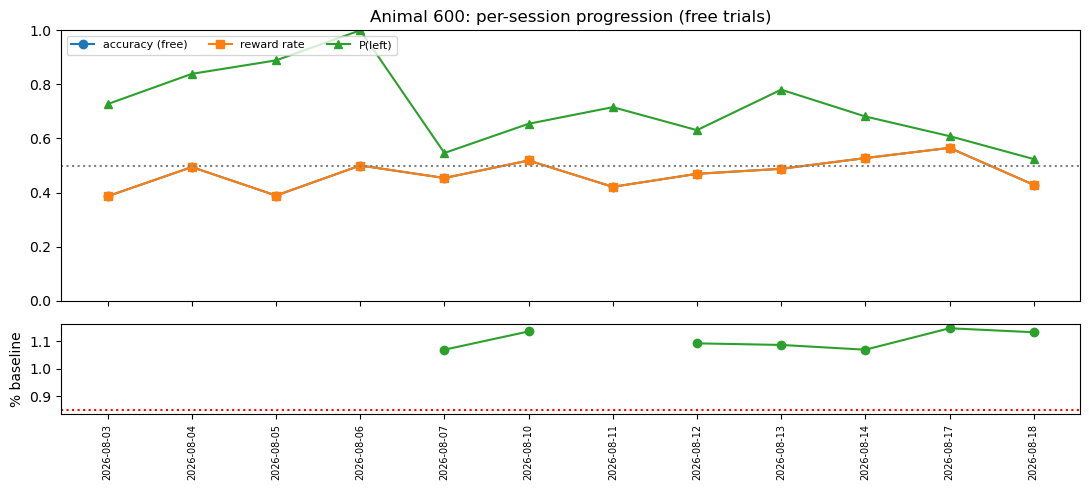

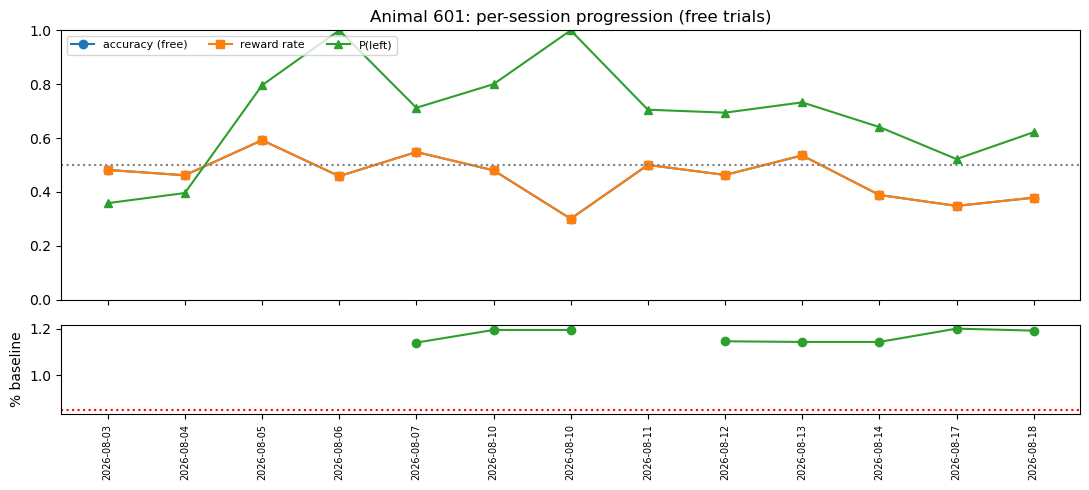

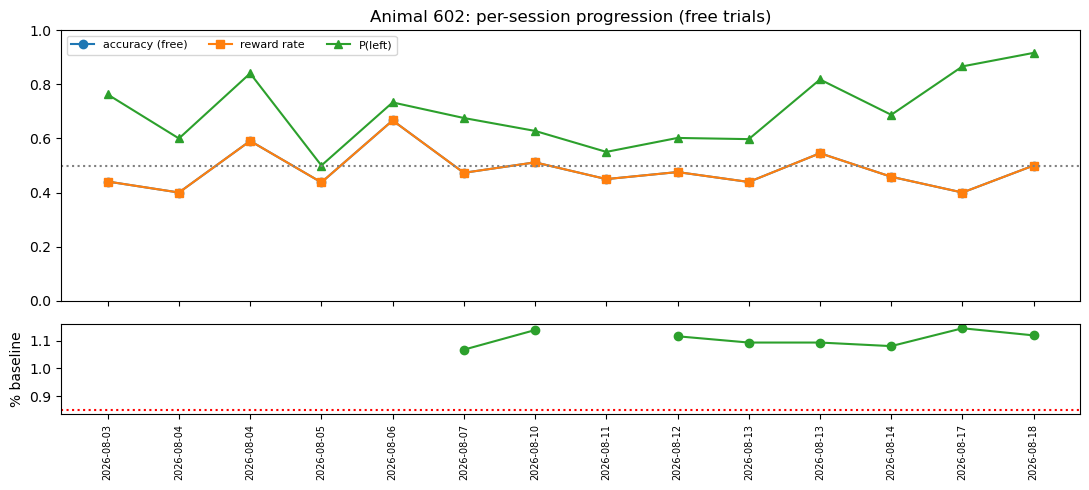

In [3]:
## 3. Per-session progression (all animals)
def plot_progression(animal):
    s = summ[summ["animal"] == animal].reset_index(drop=True)
    if s.empty:
        print("no data for", animal)
        return
    fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True,
                           gridspec_kw={"height_ratios": [3, 1]})
    x = range(len(s))
    ax[0].plot(x, s["accuracy"], "-o", label="accuracy (free)")
    ax[0].plot(x, s["reward_rate"], "-s", label="reward rate")
    ax[0].plot(x, s["side_bias_left"], "-^", label="P(left)")
    ax[0].axhline(0.5, ls=":", c="gray")
    ax[0].set_ylim(0, 1)
    ax[0].legend(loc="upper left", ncol=3, fontsize=8)
    ax[0].set_title(f"Animal {animal}: per-session progression (free trials)")

    ses = data.sessions[data.sessions["animal"] == animal].set_index("session_id")
    pct = [ses["pct_baseline"].get(sid, np.nan) for sid in s["session_id"]]
    ax[1].plot(x, pct, "-o", color="tab:green")
    ax[1].set_ylabel("% baseline")
    ax[1].axhline(0.85, ls=":", c="red")
    ax[1].set_xticks(list(x))
    ax[1].set_xticklabels(s["date"], rotation=90, fontsize=7)
    plt.tight_layout()
    plt.show()


for a in ANIMALS:
    plot_progression(a)

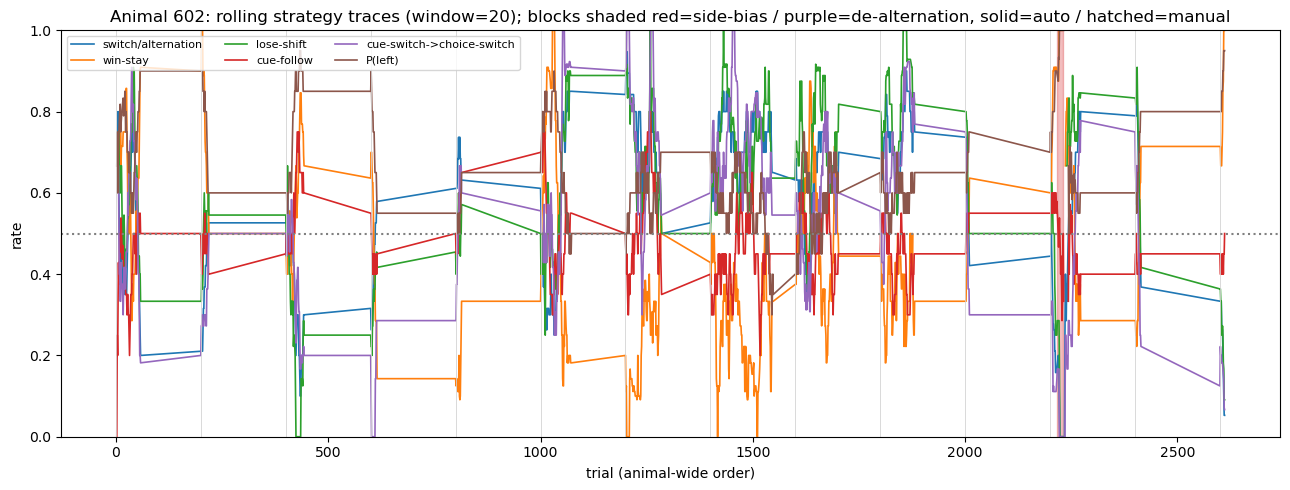

In [4]:
## 4. Rolling strategy traces (blocks shaded)  -- ANIMAL
_KIND_COLOR = {"side_bias": "tab:red", "alternation": "tab:purple"}


def plot_traces(animal, window=WINDOW):
    sig = animal_signals(animal)
    res = rolling_metrics.build_traces(sig, window=window)
    tr = res.traces
    if tr.empty:
        print("no data for", animal)
        return res
    fig, ax = plt.subplots(figsize=(13, 5))
    for col, lab in [("switch_rate", "switch/alternation"),
                     ("win_stay", "win-stay"), ("lose_shift", "lose-shift"),
                     ("cue_follow", "cue-follow"),
                     ("cue_switch_tracks", "cue-switch->choice-switch"),
                     ("side_bias_left", "P(left)")]:
        ax.plot(tr["seq"], tr[col], label=lab, lw=1.2)
    for b in res.blocks:
        color = _KIND_COLOR.get(b["kind"], "gray")
        ax.axvspan(b["start_seq"] - 0.5, b["end_seq"] + 0.5, color=color,
                   alpha=0.30 if b["trigger"] == "auto" else 0.12,
                   hatch=None if b["trigger"] == "auto" else "//")
    for sb in res.session_bounds:
        ax.axvline(sb["start_seq"], color="lightgray", lw=0.6)
    ax.set_ylim(0, 1)
    ax.axhline(0.5, ls=":", c="gray")
    ax.set_xlabel("trial (animal-wide order)")
    ax.set_ylabel("rate")
    ax.set_title(f"Animal {animal}: rolling strategy traces (window={window}); "
                 "blocks shaded red=side-bias / purple=de-alternation, "
                 "solid=auto / hatched=manual")
    ax.legend(ncol=3, fontsize=8, loc="upper left")
    plt.tight_layout()
    plt.show()
    return res


res_animal = plot_traces(ANIMAL)

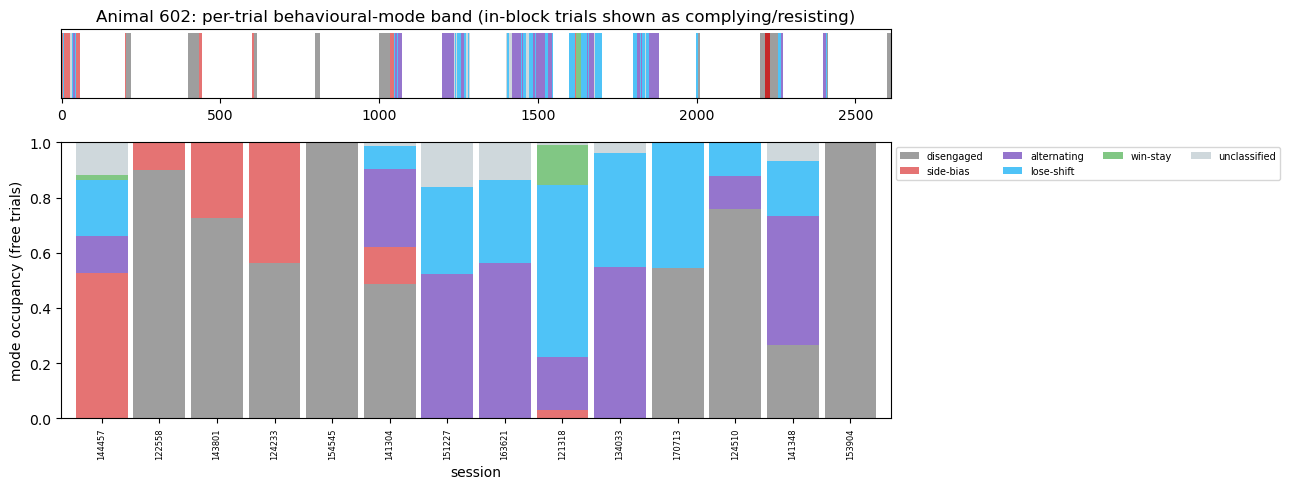

In [5]:
## 5. Behavioural-mode decomposition  -- ANIMAL
MODE_COLORS = {
    "disengaged": "#9e9e9e", "non-stem": "#8d6e63", "side-bias": "#e57373",
    "alternating": "#9575cd", "lose-shift": "#4fc3f7", "win-stay": "#81c784",
    "cue-following": "#ffb300", "unclassified": "#cfd8dc",
    "complying": "#455a64", "resisting": "#c62828",
}


def plot_mode_band(animal, res):
    tr = res.traces
    if tr.empty:
        print("no data for", animal)
        return None
    lab = mode_label.label_modes(tr, THRESHOLDS, has_excursions=HAS_EXC)
    fig, ax = plt.subplots(2, 1, figsize=(13, 5),
                           gridspec_kw={"height_ratios": [1, 4]})
    seq = lab["seq"].to_numpy()
    colors = [MODE_COLORS.get(m, "#000000") for m in lab["mode"]]
    ax[0].bar(seq, np.ones(len(seq)), width=1.0, color=colors, linewidth=0)
    ax[0].set_yticks([])
    ax[0].set_xlim(seq.min() - 0.5, seq.max() + 0.5)
    ax[0].set_title(f"Animal {animal}: per-trial behavioural-mode band "
                    "(in-block trials shown as complying/resisting)")
    occ = mode_label.mode_occupancy(lab)
    if not occ.empty:
        occ.plot(kind="bar", stacked=True, ax=ax[1], width=0.9,
                 color=[MODE_COLORS.get(c, "#000000") for c in occ.columns])
        ax[1].set_ylabel("mode occupancy (free trials)")
        ax[1].set_xlabel("session")
        ax[1].set_xticklabels([s[-6:] for s in occ.index], rotation=90, fontsize=6)
        ax[1].legend(ncol=4, fontsize=7, bbox_to_anchor=(1.0, 1.0))
    plt.tight_layout()
    plt.show()
    return lab

     
lab_animal = plot_mode_band(ANIMAL, res_animal)

Animal 602: 1 auto-block transitions; 0% changed dominant mode


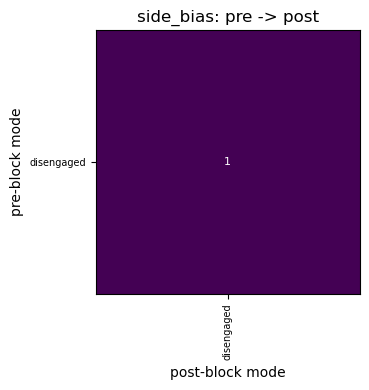

In [6]:
## 6. Peri-intervention transitions (AUTO blocks only)  -- ANIMAL
def plot_peri(animal, res, lab):
    if lab is None or not res.blocks:
        print("no blocks for", animal)
        return None
    pt = intervention_response.peri_transitions(
        lab, res.blocks, pre_window=PRE_POST, post_window=PRE_POST)
    if pt.empty:
        print("no auto-block transitions for", animal)
        return pt
    print(f"Animal {animal}: {len(pt)} auto-block transitions; "
          f"{pt['changed'].mean() * 100:.0f}% changed dominant mode")
    kinds = list(pt["kind"].unique())
    fig, axes = plt.subplots(1, len(kinds), figsize=(5 * len(kinds), 4),
                             squeeze=False)
    for ax, k in zip(axes[0], kinds):
        m = intervention_response.transition_matrix(pt, kind=k)
        ax.imshow(m.values, cmap="viridis")
        ax.set_xticks(range(len(m.columns)))
        ax.set_xticklabels(m.columns, rotation=90, fontsize=7)
        ax.set_yticks(range(len(m.index)))
        ax.set_yticklabels(m.index, fontsize=7)
        ax.set_title(f"{k}: pre -> post")
        ax.set_xlabel("post-block mode")
        ax.set_ylabel("pre-block mode")
        for (i, j), v in np.ndenumerate(m.values):
            ax.text(j, i, int(v), ha="center", va="center",
                    color="w", fontsize=8)
    plt.tight_layout()
    plt.show()
    return pt

    
pt_animal = plot_peri(ANIMAL, res_animal, lab_animal)

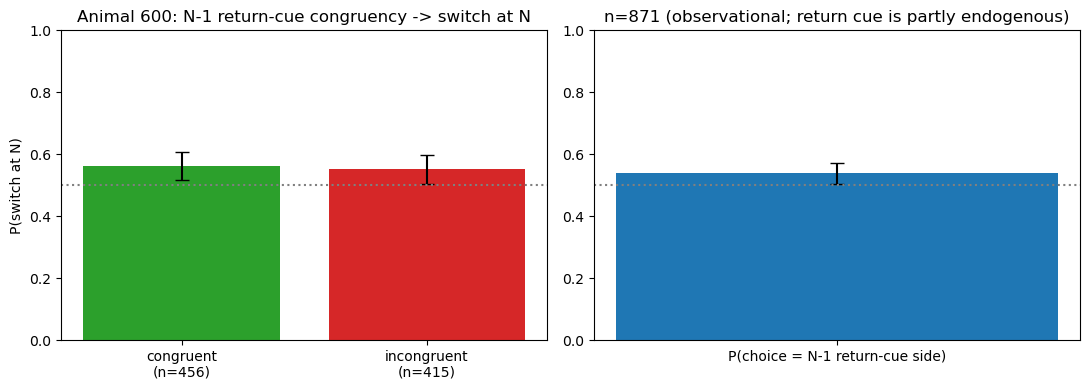

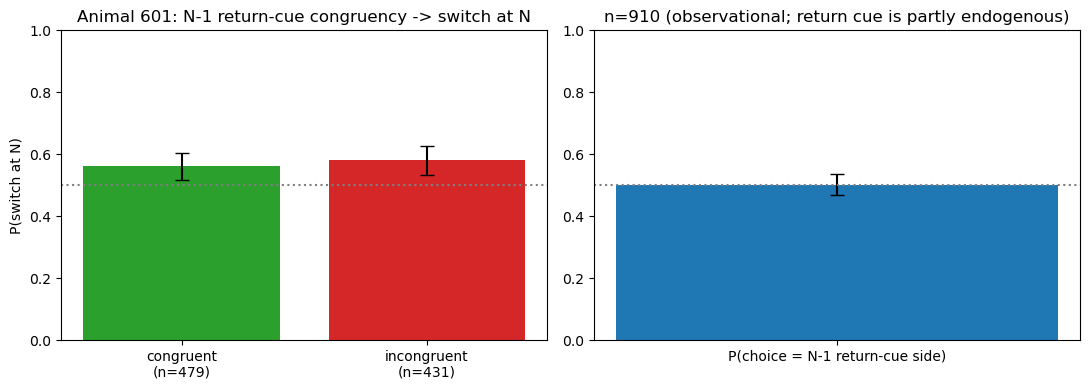

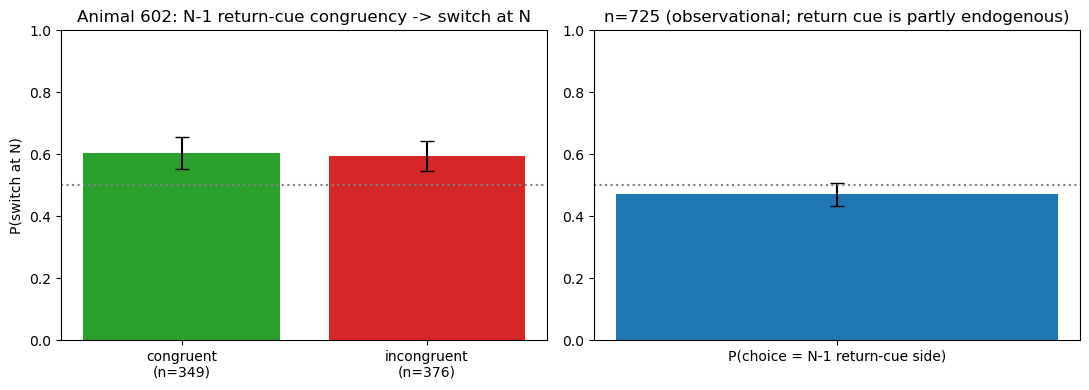

In [7]:
## 7. Return-cue carryover: does N-1's return cue bias choice/switch at N?
def _wilson(k, n):
    if n == 0:
        return np.nan, np.nan, np.nan
    p = k / n
    z = 1.96
    d = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return p, centre - half, centre + half


def return_cue_panel(animal):
    sig = animal_signals(animal)
    c = sig[choice_signals.bool_series(sig["own_pair"])].copy()
    c = c[c["prev_return_cue_congruent"].notna() & c["switch"].notna()]
    if c.empty:
        print("no usable pairs for", animal)
        return
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    labels, ps, lo_err, hi_err = [], [], [], []
    for cong, color in [(True, "tab:green"), (False, "tab:red")]:
        sub = c[c["prev_return_cue_congruent"] == cong]
        k, n = int(choice_signals.bool_series(sub["switch"]).sum()), len(sub)
        p, lo, hi = _wilson(k, n)
        labels.append(f"{'congruent' if cong else 'incongruent'}\n(n={n})")
        ps.append(p)
        lo_err.append(p - lo)
        hi_err.append(hi - p)
    ax[0].bar(labels, ps, yerr=[lo_err, hi_err], capsize=5,
              color=["tab:green", "tab:red"])
    ax[0].axhline(0.5, ls=":", c="gray")
    ax[0].set_ylim(0, 1)
    ax[0].set_ylabel("P(switch at N)")
    ax[0].set_title(f"Animal {animal}: N-1 return-cue congruency -> switch at N")

    cc = c[c["prev_return_cue_side"].notna()]
    match = (cc["choice"] == cc["prev_return_cue_side"])
    p, lo, hi = _wilson(int(match.sum()), len(match))
    ax[1].bar(["P(choice = N-1 return-cue side)"], [p],
              yerr=[[p - lo], [hi - p]], capsize=5, color="tab:blue")
    ax[1].axhline(0.5, ls=":", c="gray")
    ax[1].set_ylim(0, 1)
    ax[1].set_title(f"n={len(match)} (observational; return cue is partly endogenous)")
    plt.tight_layout()
    plt.show()


for a in ANIMALS:
    return_cue_panel(a)

C:\Users\Celine\anaconda3\envs\drieu_t_maze\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


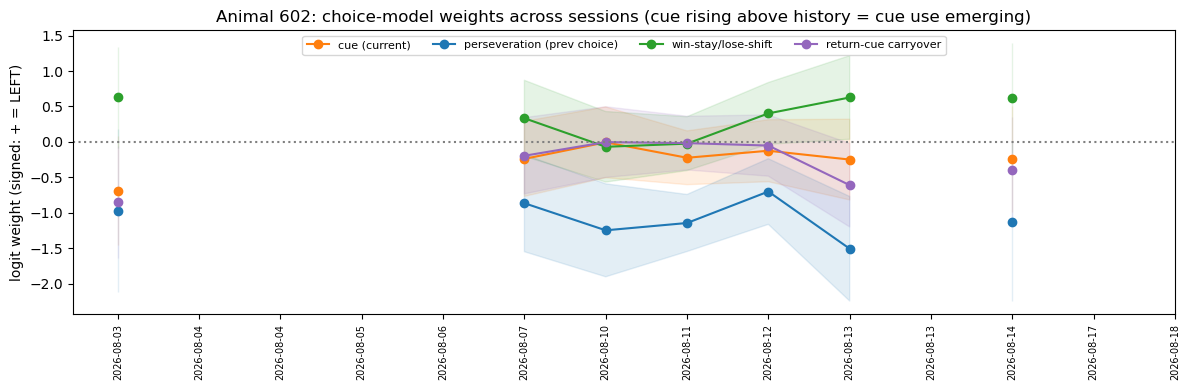

,session_id,date,n,cue,cue_lo,cue_hi,cue_p,persev,persev_lo,persev_hi,...,winstay,winstay_lo,winstay_hi,winstay_p,returncue,returncue_lo,returncue_hi,returncue_p,bias,converged
0,602_20260803_144457,2026-08-03,58,-0.688683,-1.457479,0.080114,0.079136,-0.971423,-2.118575,0.175729,...,0.627060,-0.090607,1.344727,0.086802,-0.848263,-1.632860,-0.063665,0.034090,2.105489,True
1,602_20260804_122558,2026-08-04,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,602_20260804_143801,2026-08-04,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,602_20260805_124233,2026-08-05,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,602_20260806_154545,2026-08-06,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,602_20260807_141304,2026-08-07,73,-0.239841,-0.769859,0.290176,0.375125,-0.865663,-1.550413,-0.180913,...,0.333655,-0.202107,0.869418,0.222237,-0.195972,-0.734129,0.342185,0.475395,1.194271,True
6,602_20260810_151227,2026-08-10,84,-0.006219,-0.505930,0.493492,0.980540,-1.248479,-1.904652,-0.592306,...,-0.069421,-0.567642,0.428800,0.784780,-0.003209,-0.502254,0.495836,0.989943,1.018344,True
7,602_20260811_163621,2026-08-11,146,-0.224241,-0.604002,0.155519,0.247141,-1.145178,-1.547992,-0.742363,...,-0.025093,-0.405236,0.355050,0.897061,-0.017423,-0.396593,0.361746,0.928238,0.432801,True
8,602_20260812_121318,2026-08-12,101,-0.124982,-0.562657,0.312694,0.575696,-0.700990,-1.164490,-0.237490,...,0.402066,-0.033805,0.837938,0.070614,-0.052013,-0.484103,0.380077,0.813487,0.630498,True
9,602_20260813_134033,2026-08-13,81,-0.249696,-0.819358,0.319966,0.390287,-1.508345,-2.246282,-0.770408,...,0.626757,0.036490,1.217023,0.037422,-0.611084,-1.200817,-0.021352,0.042263,1.030128,True


In [8]:
## 8. Choice-vs-history model across sessions (free trials)
_TERM_COLOR = {"cue": "tab:orange", "persev": "tab:blue",
               "winstay": "tab:green", "returncue": "tab:purple"}
_TERM_LABEL = {"cue": "cue (current)", "persev": "perseveration (prev choice)",
               "winstay": "win-stay/lose-shift", "returncue": "return-cue carryover"}


def plot_choice_model(animal):
    if not choice_model.HAS_STATSMODELS:
        import sys
        print("statsmodels unavailable in THIS notebook's kernel.")
        print(f"  kernel interpreter: {sys.executable}")
        if choice_model.STATSMODELS_IMPORT_ERROR:
            print(f"  import error:       {choice_model.STATSMODELS_IMPORT_ERROR}")
        print("  A `pip install` in your conda shell only helps if that env is the")
        print("  kernel above. Install into THIS interpreter, then restart the kernel:")
        print(f'    "{sys.executable}" -m pip install statsmodels')
        return None
    res = choice_model.fit_by_session(animal_signals(animal))
    if res.empty:
        print("no data for", animal)
        return res
    fig, ax = plt.subplots(figsize=(12, 4))
    x = range(len(res))
    for term, color in _TERM_COLOR.items():
        if term not in res.columns:
            continue
        ax.plot(x, res[term], "-o", color=color, label=_TERM_LABEL[term])
        lo, hi = res.get(f"{term}_lo"), res.get(f"{term}_hi")
        if lo is not None:
            ax.fill_between(x, lo, hi, color=color, alpha=0.12)
    ax.axhline(0, c="gray", ls=":")
    ax.set_xticks(list(x))
    ax.set_xticklabels(res["date"], rotation=90, fontsize=7)
    ax.set_ylabel("logit weight (signed: + = LEFT)")
    ax.set_title(f"Animal {animal}: choice-model weights across sessions "
                 "(cue rising above history = cue use emerging)")
    ax.legend(ncol=4, fontsize=8)
    plt.tight_layout()
    plt.show()
    return res


cm_animal = plot_choice_model(ANIMAL)
cm_animal